In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_percentage_error
import tensorflow as tf
from keras import Model
from keras.layers import Input, Dense, Dropout
from keras.layers import LSTM
from pathlib import Path

In [2]:
file_path = 'data/gold_cad.csv'

df = pd.read_csv(file_path)

In [3]:
df

,Date,Close
0,1/2/2001,400.90
1,1/3/2001,401.68
2,1/4/2001,400.51
3,1/5/2001,401.92
4,1/8/2001,400.42
...,...,...
4956,5/27/2020,2374.59
4957,5/28/2020,2378.61
4958,5/29/2020,2412.15
4959,6/1/2020,2375.54


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4961 entries, 0 to 4960
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    4961 non-null   object 
 1   Close   4961 non-null   float64
dtypes: float64(1), object(1)
memory usage: 77.6+ KB


In [5]:
df['Date'] = pd.to_datetime(df['Date'])
df.sort_values(by='Date', ascending=True, inplace=True)
df.reset_index(drop=True, inplace=True)

In [6]:
df.head()

,Date,Close
0,2001-01-02,400.90
1,2001-01-03,401.68
2,2001-01-04,400.51
3,2001-01-05,401.92
4,2001-01-08,400.42


In [7]:
df.duplicated().sum()

0

In [8]:
df.isnull().sum()

,0
Date,0
Close,0


In [9]:
test_size = df[df.Date.dt.year==2019].shape[0]
test_size

265

In [10]:
scaler = MinMaxScaler()
scaler.fit(df.Close.values.reshape(-1,1))

MinMaxScaler()

In [11]:
window_size = 60

In [12]:
train_data = df.Close[:-test_size]
train_data = scaler.transform(train_data.values.reshape(-1,1))

In [13]:
X_train = []
y_train = []

for i in range(window_size, len(train_data)):
    X_train.append(train_data[i-60:i, 0])
    y_train.append(train_data[i, 0])

In [14]:
test_data = df.Close[-test_size-60:]
test_data = scaler.transform(test_data.values.reshape(-1,1))

In [15]:
X_test = []
y_test = []

for i in range(window_size, len(test_data)):
    X_test.append(test_data[i-60:i, 0])
    y_test.append(test_data[i, 0])

In [16]:
X_train = np.array(X_train)
X_test  = np.array(X_test)
y_train = np.array(y_train)
y_test  = np.array(y_test)

In [17]:
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test  = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))
y_train = np.reshape(y_train, (-1,1))
y_test  = np.reshape(y_test, (-1,1))

In [18]:
print('X_train Shape: ', X_train.shape)
print('y_train Shape: ', y_train.shape)
print('X_test Shape:  ', X_test.shape)
print('y_test Shape:  ', y_test.shape)

X_train Shape:  (4636, 60, 1)
y_train Shape:  (4636, 1)
X_test Shape:   (265, 60, 1)
y_test Shape:   (265, 1)


In [19]:
def define_model():
    input1 = Input(shape=(window_size,1))
    x = LSTM(units = 64, return_sequences=True)(input1)
    x = Dropout(0.2)(x)
    x = LSTM(units = 64, return_sequences=True)(x)
    x = Dropout(0.2)(x)
    x = LSTM(units = 64)(x)
    x = Dropout(0.2)(x)
    x = Dense(32, activation='softmax')(x)
    dnn_output = Dense(1)(x)

    model = Model(inputs=input1, outputs=[dnn_output])
    model.compile(loss='mean_squared_error', optimizer='adam', metrics=[
        "accuracy",
        tf.keras.metrics.TruePositives(name = "TP"),
        tf.keras.metrics.TrueNegatives(name = "TN"),
        tf.keras.metrics.FalsePositives(name = "FP"),
        tf.keras.metrics.FalseNegatives(name = "FN"),
        tf.keras.metrics.Precision(name = "Precision"),
        tf.keras.metrics.Recall(name = "Recall"),
        tf.keras.metrics.AUC(name = "AUC"),
    ])
    model.summary()

    return model

In [55]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 60, 1)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 60, 64)              │          16,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 60, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 60, 64)              │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 60, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_2 (LSTM)                        │ (None, 64)                  │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 255,173 (996.77 KB)

 Trainable params: 85,057 (332.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 170,116 (664.52 KB)

In [20]:
model = define_model()
history = model.fit(X_train, y_train, epochs=1000, batch_size=1000, validation_split=0.1, verbose=1)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 60, 1)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 60, 64)              │          16,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 60, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 60, 64)              │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 60, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_2 (LSTM)                        │ (None, 64)                  │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 85,057 (332.25 KB)

 Trainable params: 85,057 (332.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 428ms/step - AUC: 0.0000e+00 - FN: 3057.3333 - FP: 0.0000e+00 - Precision: 0.0000e+00 - Recall: 0.0000e+00 - TN: 0.0000e+00 - TP: 0.0000e+00 - accuracy: 0.0000e+00 - loss: 0.1540 - val_AUC: 0.0000e+00 - val_FN: 464.0000 - val_FP: 0.0000e+00 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_TN: 0.0000e+00 - val_TP: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.3629
Epoch 2/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - AUC: 0.0000e+00 - FN: 3057.3333 - FP: 0.0000e+00 - Precision: 0.0000e+00 - Recall: 0.0000e+00 - TN: 0.0000e+00 - TP: 0.0000e+00 - accuracy: 0.0000e+00 - loss: 0.1300 - val_AUC: 0.0000e+00 - val_FN: 464.0000 - val_FP: 0.0000e+00 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_TN: 0.0000e+00 - val_TP: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.2620
Epoch 3/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - AUC: 0.0000e+00 - FN: 3057.3333 - FP: 0.0000e+00 - Precision: 0.0000e+00 - Recall: 0.0000e+00 - TN: 0

In [21]:
result = model.evaluate(X_test, y_test)
y_pred = model.predict(X_test)

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - AUC: 0.0000e+00 - FN: 0.0000e+00 - FP: 0.0000e+00 - Precision: 1.0000 - Recall: 1.0000 - TN: 0.0000e+00 - TP: 168.2000 - accuracy: 0.0011 - loss: 0.0107    
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


In [22]:
#Accuracy
# from sklearn.metrics import accuracy_score

# y_rnn_pred_binary = np.round(result)

# Calculate accuracy
# print("RNN LSTM Accuracy: %.2f" % (accuracy_score(y_test , y_rnn_pred_binary)))


ValueError: Found input variables with inconsistent numbers of samples: [265, 9]

In [48]:
MAPE = mean_absolute_percentage_error(y_test, y_pred)
Accuracy = 1 - MAPE

In [27]:
print("Test Loss:", result)
print("Test MAPE:", MAPE,'%')
print("Test Accuracy:", Accuracy,'%')

Test Loss: [0.022452201694250107, 0.0037735849618911743, 265.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.0]
Test MAPE: 0.14429268934603262 %
Test Accuracy: 0.8557073106539674 %


In [28]:
y_test_true = scaler.inverse_transform(y_test)
y_test_pred = scaler.inverse_transform(y_pred)

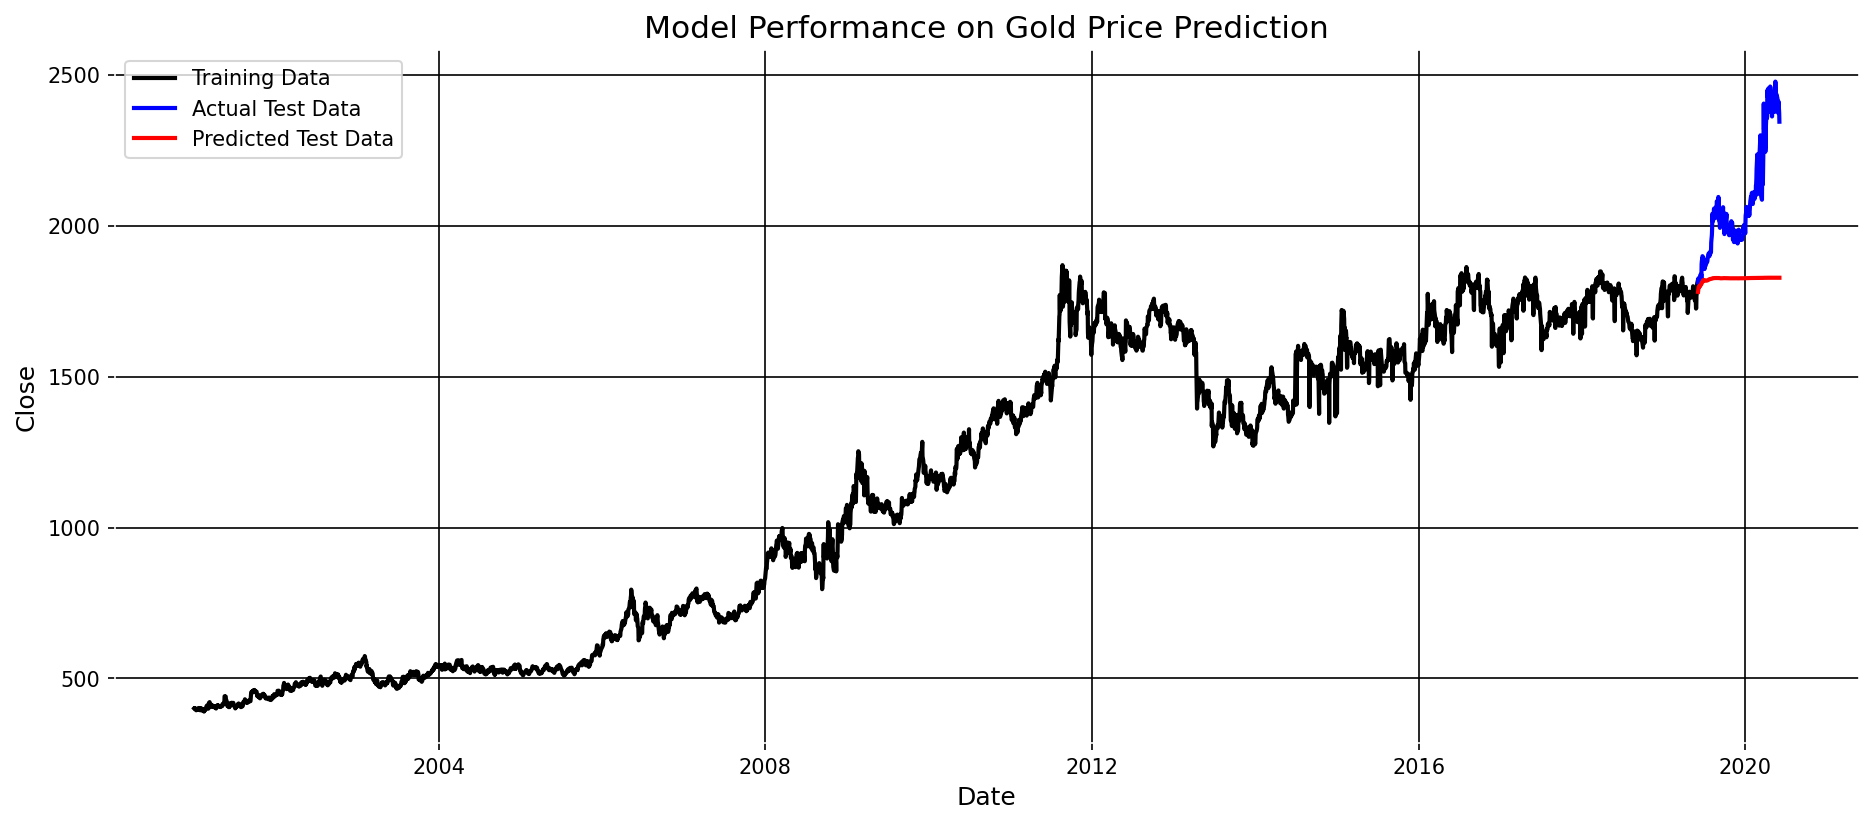

In [52]:
plt.figure(figsize=(15, 6), dpi=150)
plt.rcParams['axes.facecolor'] = 'white'
plt.rc('axes',edgecolor='white')
plt.plot(df['Date'].iloc[:-test_size], scaler.inverse_transform(train_data), color='black', lw=2)
plt.plot(df['Date'].iloc[-test_size:], y_test_true, color='blue', lw=2)
plt.plot(df['Date'].iloc[-test_size:], y_test_pred, color='red', lw=2)
plt.title('Model Performance on Gold Price Prediction', fontsize=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Close', fontsize=12)
plt.legend(['Training Data', 'Actual Test Data', 'Predicted Test Data'], loc='upper left', prop={'size': 10})
plt.grid(color='black')
plt.show()

In [35]:
#Confusion Matrix

from sklearn.metrics import confusion_matrix

In [54]:
confusion_matrix = metrics.confusion_matrix(y_test, y_pred)

print(confusion_matrix)

ValueError: continuous is not supported

In [37]:
from sklearn.metrics import classification_report

In [39]:
y_rnn_pred_binary = np.round(result)
print("Classification Report for the RNN LSTM Model")
print(classification_report(y_rnn_pred_binary , y_test))

Classification Report for the RNN LSTM Model


ValueError: Found input variables with inconsistent numbers of samples: [9, 265]

In [40]:
tn_rnn , fp_rnn , fn_rnn , tp_rnn = confusion_matrix(y_test , y_rnn_pred_binary).ravel()

#Dataframe ro display confusion matrix from The RNN LSTM Model

cm_rnn_df = pd.DataFrame(
    {
        "Positive(1)":[f"TP={tp_rnn}" , f"FP={fp_rnn}"],
        "Negative(0)":[f"FN={fn_rnn}" , f"TN={tn_rnn}"],
    },
    index=["Positive(1)" , "Negative(0)"],
)
cm_rnn_df.index.name = "Actual"
cm_rnn_df.columns.name = "Predicted"
print("Confusion Matrix From the RNN LSTM Model")
display(cm_rnn_df)

ValueError: Found input variables with inconsistent numbers of samples: [265, 9]

In [42]:
test_predictions_rnn = model.predict(X_test , batch_size=1000)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


In [44]:
from sklearn.metrics import roc_curve , auc

In [46]:
fpr_test_rnn , tpr_test_rnn , thresholds_test_rnn = roc_curve(y_test , test_predictions_rnn)

ValueError: continuous format is not supported